In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

BASE_DIR = "/content/drive/MyDrive/BrainTumor_BO_Reproduction"

print("Project folder exists:", os.path.exists(BASE_DIR))

if os.path.exists(BASE_DIR):
    print("\nProject contents:")
    print(os.listdir(BASE_DIR))

Project folder exists: True

Project contents:
['dataset', 'dataset1_final_results', 'test_images', 'Reproduction_dataset1.ipynb', 'BrainTumor_Dataset1_Prediction.ipynb ']


In [4]:
#Check your model
MODEL_PATH = os.path.join(
    BASE_DIR,
    "dataset1_final_results",
    "dataset1_final_model.keras"
)

print("Model exists:", os.path.exists(MODEL_PATH))
print("Model path:", MODEL_PATH)

Model exists: True
Model path: /content/drive/MyDrive/BrainTumor_BO_Reproduction/dataset1_final_results/dataset1_final_model.keras


In [5]:
#Load the trained model
import tensorflow as tf

model = tf.keras.models.load_model(MODEL_PATH)

print("Trained brain tumor model loaded successfully!")

Trained brain tumor model loaded successfully!


In [6]:
#Checking the input images
TEST_IMAGE_DIR = os.path.join(BASE_DIR, "test_images")

print("Test image folder exists:", os.path.exists(TEST_IMAGE_DIR))

if os.path.exists(TEST_IMAGE_DIR):
    images = os.listdir(TEST_IMAGE_DIR)

    print("\nImages available:")
    for image in images:
        print(image)

Test image folder exists: True

Images available:
glioma_image.png
meningioma_image.jpeg
no_tumor_image.webp
pitutary_image.jpeg


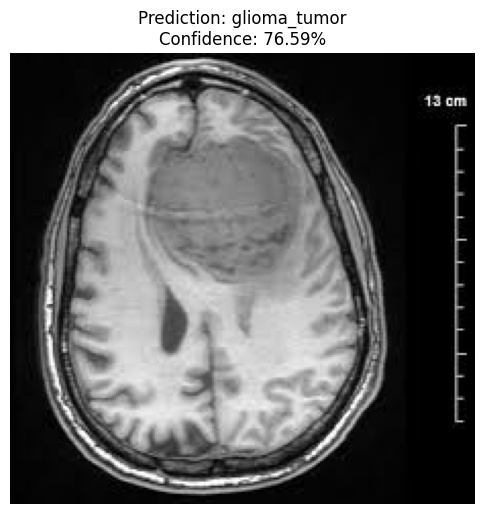

           BRAIN TUMOR CLASSIFICATION

Image: meningioma_image.jpeg

Class Probabilities:
glioma_tumor        : 76.59%
meningioma_tumor    : 0.03%
pituitary_tumor     : 0.00%
no_tumor            : 23.38%

------------------------------------------------------------
Predicted Class : glioma_tumor
Confidence      : 76.59%


In [7]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

CLASS_NAMES = [
    "glioma_tumor",
    "meningioma_tumor",
    "pituitary_tumor",
    "no_tumor"
]


image_name = "meningioma_image.jpeg"

image_path = os.path.join(
    TEST_IMAGE_DIR,
    image_name
)

img = Image.open(image_path).convert("RGB")


img_resized = img.resize((224, 224))

img_array = np.array(
    img_resized,
    dtype=np.float32
)


img_array = img_array / 255.0


img_array = np.expand_dims(
    img_array,
    axis=0
)


prediction = model.predict(
    img_array,
    verbose=0
)

probabilities = prediction[0]


predicted_index = np.argmax(probabilities)

predicted_class = CLASS_NAMES[predicted_index]

predicted_confidence = probabilities[predicted_index] * 100



plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.axis("off")

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {predicted_confidence:.2f}%"
)

plt.show()

print("=" * 60)
print("           BRAIN TUMOR CLASSIFICATION")
print("=" * 60)

print(f"\nImage: {image_name}")

print("\nClass Probabilities:")

for class_name, probability in zip(
    CLASS_NAMES,
    probabilities
):
    print(
        f"{class_name:20s}: "
        f"{probability * 100:.2f}%"
    )

print("\n" + "-" * 60)

print(f"Predicted Class : {predicted_class}")
print(f"Confidence      : {predicted_confidence:.2f}%")

print("=" * 60)